# M4 — Exploratory data analysis

**Project:** NASA Near-Earth Asteroid Hazard Analysis · **Milestone:** M4 (EXPLORE) · **Team:** Burak Avşar · Rana Yalçın · Elif Şahin

**Project question:** *Which asteroid features are linked to the "potentially hazardous" label?*

This notebook reads `data/asteroids.db` **read-only** (built by `python src/load.py` and `python src/clean.py`), writes every figure to `figures/`,
and checks at the end that the database file is byte-for-byte unchanged. Run it with **Restart & Run All**.

| Section | Brief | Explored by |
|---|---|---|
| 0. Parameters | every choice in one place | Burak Avşar |
| 1. Raw versus cleaned | §2.1 | Burak Avşar |
| 2. The question and its summary | §2.2 | Burak Avşar |
| 3. Shape | §2.3 | Burak Avşar |
| 4. Coverage, denominators and the flag filter | §2.4 | Rana Yalçın |
| 5. Time | §2.5 | Rana Yalçın |
| 6. Relationships | §2.6 | Elif Şahin |
| 7. One comparison, with an interval | §2.7 | Elif Şahin |
| 8. Findings | §2.8 | Burak Avşar (collects) · everyone adds rows |
| 9. Decisions and database check | | Burak Avşar |

**Team rule for this file:** one person edits it at a time (pull → add your section → Restart & Run All → push → tell the group).

## 0. Parameters — every choice in one place

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from explore import DB_PATH, bootstrap_ci, connect_ro, db_fingerprint, ecdf, finish, load_query, query, style

# ---- units
LD_KM = 384_400                 # one lunar distance (mean Earth-Moon distance), the natural unit for close passes
AU_KM = 149_597_870.7           # one astronomical unit (IAU 2012)
PHA_MOID_LD = 0.05 * AU_KM / LD_KM  # NASA's hazard limit 0.05 AU = 19.5 LD, used as a reference line

# ---- flag filter for the key number (named in every query and caption)
#      ok + unusual_*: unusual_low values are the closest real passes, the events this question is about
KEY_FILTER = {"include_unusual": 1, "include_predicted": 1, "exclude_label_mismatch": 0}
KEY_FILTER_TEXT = "flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches"

# ---- section 3 (shape)
BIN_WIDTHS_LD = (1, 5, 10)      # histogram bin widths tried, in lunar distances
CHOSEN_BIN_LD = 5               # the one reported (justified in section 3)
CLOSE_PASS_LD = 1               # 'closer than the Moon': threshold for the alternative summary

# ---- sections 4-7 (Rana Yalçın and Elif Şahin set these)
MIN_EARTH_APPROACHES = 3        # minimum qualifying Earth approaches for coverage-qualified summaries
SEED = 42                       # random seed for every bootstrap
N_BOOT = 2000                   # bootstrap resamples
MIN_CLASS_N = 10                # smallest group (per label, per orbit class) given a correlation or an interval
N_A_BINS = 10                   # equal-count bins of semi-major axis for the binned medians in section 6

style()
DB_FINGERPRINT_BEFORE = db_fingerprint()
con = connect_ro()
print("database:", Path(DB_PATH).relative_to(ROOT), "| sha256", DB_FINGERPRINT_BEFORE[:16], "| opened read-only")

database: data/asteroids.db | sha256 82630325ee170662 | opened read-only


## 1. Raw versus cleaned: the key number

**Key number:** the **median closest Earth approach** of hazardous and of non-hazardous asteroids, in lunar distances (LD).
For each asteroid we take its closest listed pass to Earth in NASA's 1900–2200 window, then take the median over the asteroids of each group.
It is computed twice: on the M2 tables as loaded, and on the cleaned layer with the flag filter we actually use.

In [2]:
raw_sql = load_query("closest_earth_raw")
clean_sql = load_query("closest_earth_clean")
print(raw_sql)
print(clean_sql)

-- Question: how close does each asteroid come to Earth, by hazard label? (raw M2 tables, as loaded)
-- Grain: one row per asteroid that has at least one Earth approach.
-- Flag filter: none (M2 tables have no flags); every asteroid row counts, including duplicate NASA ids.
SELECT
    a.asteroid_key,
    a.is_potentially_hazardous AS hazardous,
    MIN(p.miss_distance_km)    AS closest_km,
    COUNT(*)                   AS n_earth_approaches
FROM asteroids AS a
JOIN approaches AS p ON p.asteroid_key = a.asteroid_key
WHERE p.orbiting_body = 'Earth'
GROUP BY a.asteroid_key, a.is_potentially_hazardous;

-- Question: how close does each asteroid come to Earth, by hazard label? (cleaned layer)
-- Grain: one row per resolved asteroid that has at least one Earth approach.
-- Flag filter (parameters):
--   identity_flag = 'ok'                     duplicate NASA ids counted once (their approaches are the same events)
--   is_potentially_hazardous IS NOT NULL     label present (label_rule_mismat

In [3]:
raw = query(con, raw_sql)
clean = query(con, clean_sql, KEY_FILTER)
for d in (raw, clean):
    d["closest_ld"] = d["closest_km"] / LD_KM

def key_number(d):
    return d.groupby("hazardous")["closest_ld"].agg(n="size", median="median").round(2)

both = pd.concat({"raw (M2 tables)": key_number(raw), "cleaned (KEY_FILTER)": key_number(clean)}, axis=1)
both.index = both.index.map({0: "not hazardous", 1: "hazardous"})
both

raw (M2 tables)        cleaned (KEY_FILTER)       
                            n median                    n median
hazardous                                                       
not hazardous            3127  40.22                 3127  40.22
hazardous                1030  13.08                 1027  13.07

In [4]:
# What exactly differs between the two inputs?
only_raw = set(raw.asteroid_key) - set(clean.asteroid_key)
dup = query(con, "SELECT asteroid_key, identity_flag FROM asteroid_clean WHERE identity_flag <> 'ok'")
print("asteroids in raw but not in cleaned:", len(only_raw), "| of which duplicate NASA ids:", len(only_raw & set(dup.asteroid_key)))
print("cleaned asteroids whose closest value differs from raw:",
      int((raw.set_index("asteroid_key").closest_km.reindex(clean.asteroid_key).values != clean.closest_km.values).sum()))

asteroids in raw but not in cleaned: 3 | of which duplicate NASA ids: 3
cleaned asteroids whose closest value differs from raw: 0


**Raw vs cleaned.** Cleaning changes the inputs but not the answer. The cleaned version drops the **3 duplicate NASA ids** (section 5 of the M3 report);
their approaches are the same events as those of the numbered asteroid, so the raw table counts three hazardous asteroids twice (n 1,030 → 1,027).
No asteroid's closest distance changes, because the cleaned layer found no invalid miss distance and the flag filter keeps the `unusual_*` values.
So the hazardous median moves by 0.01 LD (13.08 → 13.07) and the non-hazardous one not at all — a result, not a non-event: our cleaning was about
coverage and identity, not bad numbers, and this key number is robust to it.

## 2. The question and its summary

**Question (one sentence):** *How much closer to Earth do potentially hazardous asteroids typically come than non-hazardous ones?*

**Summary: the median** of each asteroid's closest approach. Why the median: the question asks about the *typical* asteroid; closest distances are right-skewed
(section 3), so the mean is pulled up by a long tail of distant passes; and each asteroid counts once, whatever its number of approaches.

**Alternative summaries of the same variable:** the mean; the 10th percentile (the close tail); and the **share of asteroids that ever pass closer than the Moon (1 LD)**.
Do they rank the groups the same way?

In [5]:
def summaries(d):
    g = d.groupby("hazardous")["closest_ld"]
    out = pd.DataFrame({
        "n": g.size(),
        "median_LD": g.median(),
        "mean_LD": g.mean(),
        "p10_LD": g.quantile(0.10),
        "share_closer_than_moon_%": g.apply(lambda s: 100 * (s < CLOSE_PASS_LD).mean()),
        "n_closer_than_moon": g.apply(lambda s: int((s < CLOSE_PASS_LD).sum())),
        "share_within_0.05AU_%": g.apply(lambda s: 100 * (s <= PHA_MOID_LD).mean()),
    }).round(2)
    out.index = out.index.map({0: "not hazardous", 1: "hazardous"})
    return out

S = summaries(clean)
S

,n,median_LD,mean_LD,p10_LD,share_closer_than_moon_%,n_closer_than_moon,share_within_0.05AU_%
hazardous,,,,,,,
not hazardous,3127,40.22,46.74,6.28,1.28,40,25.26
hazardous,1027,13.07,16.16,4.28,1.17,12,74.59


In [6]:
# Is the 'closer than the Moon' tie made of different asteroids? Size (H) of the asteroids that pass inside 1 LD
h = query(con, "SELECT asteroid_key, absolute_magnitude_h FROM asteroid_clean")
close = clean[clean.closest_ld < CLOSE_PASS_LD].merge(h, on="asteroid_key")
close.groupby("hazardous")["absolute_magnitude_h"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
hazardous,,,,,,,,
0,40.0,26.92,2.29,17.81,26.18,26.85,28.67,30.10
1,12.0,20.25,1.26,18.28,19.25,20.45,21.20,21.91


**Finding — the summary decides the ranking.** By the **median** (and the mean and the 10th percentile), hazardous asteroids come about **three times closer**
to Earth than non-hazardous ones. By the **share that ever passes closer than the Moon**, the two groups are **level** (about 1.2–1.3% each).
The two rankings answer different questions: the median asks *how close does a typical asteroid of the group come*; the share asks *how often does
a really close pass happen*. The asteroids that pass inside 1 LD without the label are **small**: 39 of the 40 have H > 22 (diameter below ~140 m),
so they fail the size half of NASA's definition however close they come. The label is about *size and orbit*, not about the closest pass on record.

## 3. Shape

The key variable is shown in two ways that do not share the same weakness: **histograms** (with the bin width chosen after trying three) and an **ECDF**
on a log scale (no bins at all, and it shows the close tail that a linear histogram squeezes into one bar).

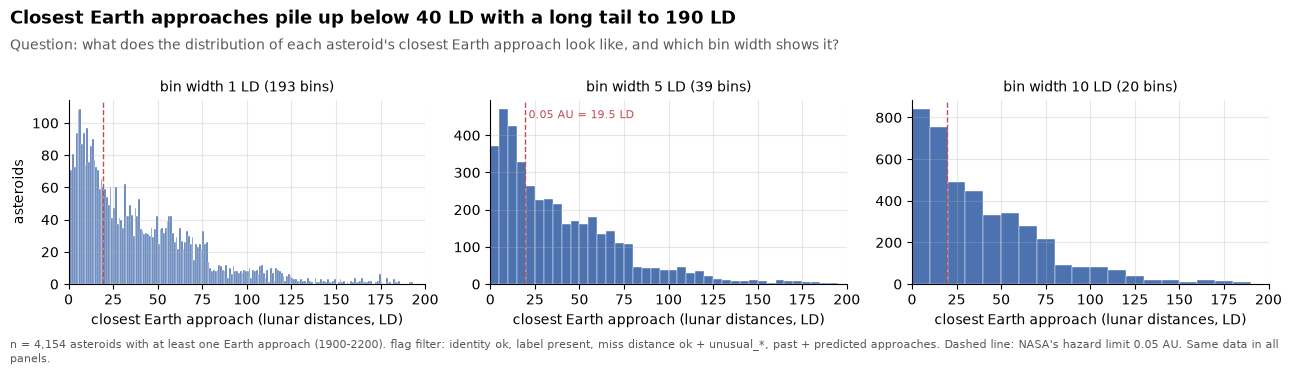

figures/m4_fig1_hist_bin_widths.png


In [7]:
# Three bin widths, same data, same axes
x = clean["closest_ld"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, w in zip(axes, BIN_WIDTHS_LD):
    bins = np.arange(0, x.max() + w, w)
    ax.hist(x, bins=bins, color="#4C72B0", edgecolor="white", linewidth=0.3)
    ax.axvline(PHA_MOID_LD, color="#C44E52", ls="--", lw=1)
    ax.set_title(f"bin width {w} LD ({len(bins) - 1} bins)", fontsize=10, fontweight="normal")
    ax.set_xlabel("closest Earth approach (lunar distances, LD)")
    ax.set_xlim(0, 200)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("asteroids")
axes[1].text(PHA_MOID_LD + 2, axes[1].get_ylim()[1] * 0.9, "0.05 AU = 19.5 LD", color="#C44E52", fontsize=8)
path = finish(fig, "m4_fig1_hist_bin_widths",
              "Closest Earth approaches pile up below 40 LD with a long tail to 190 LD",
              "Question: what does the distribution of each asteroid's closest Earth approach look like, and which bin width shows it?",
              f"n = {len(x):,} asteroids with at least one Earth approach (1900-2200). {KEY_FILTER_TEXT}. "
              "Dashed line: NASA's hazard limit 0.05 AU. Same data in all panels.")
plt.show()
print(path.relative_to(ROOT))

**Bin width.** At **1 LD** (193 bins) the bars are noisy: the tail bins hold a handful of asteroids each and the eye follows the noise.
At **10 LD** the first bin swallows the rise from 0 to the peak at 5–10 LD. **5 LD** is the coarsest width that keeps the three features every panel hints at:
the peak at 5–10 LD, the drop just after **19.5 LD** (NASA's 0.05 AU limit) and a **step at ~78 LD**. It is the width used for the group comparison.

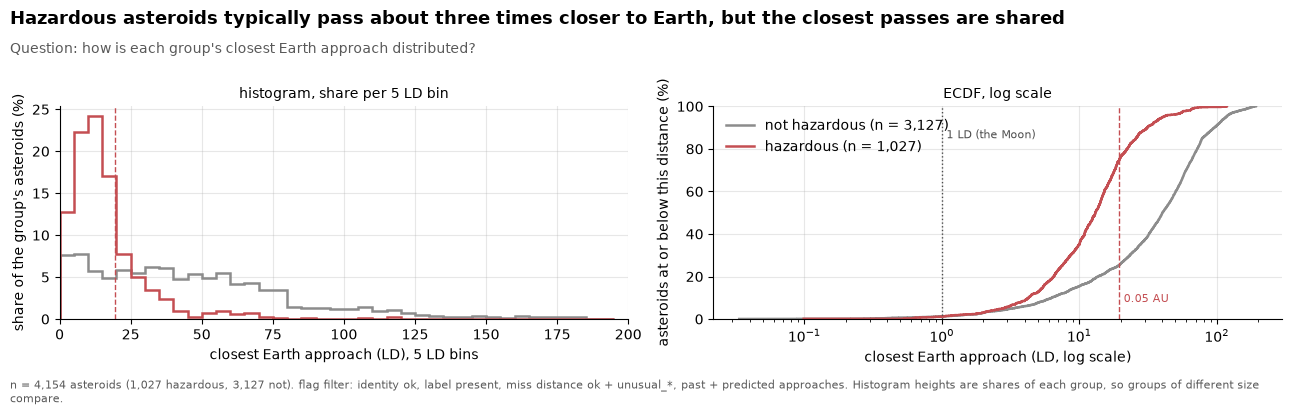

figures/m4_fig2_closest_by_group.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = {0: "#8C8C8C", 1: "#C44E52"}
names = {0: "not hazardous", 1: "hazardous"}
bins = np.arange(0, clean.closest_ld.max() + CHOSEN_BIN_LD, CHOSEN_BIN_LD)
for hz in (0, 1):
    s = clean.loc[clean.hazardous == hz, "closest_ld"]
    axes[0].hist(s, bins=bins, weights=np.full(len(s), 100 / len(s)), histtype="step", lw=1.8,
                 color=colors[hz], label=f"{names[hz]} (n = {len(s):,})")
    xs, ys = ecdf(s)
    axes[1].step(xs, ys * 100, where="post", color=colors[hz], lw=1.8, label=f"{names[hz]} (n = {len(s):,})")
for ax in axes:
    ax.axvline(PHA_MOID_LD, color="#C44E52", ls="--", lw=1)
axes[1].axvline(CLOSE_PASS_LD, color="0.3", ls=":", lw=1)
axes[1].text(CLOSE_PASS_LD * 1.08, 85, "1 LD (the Moon)", fontsize=8, color="0.3")
axes[1].text(PHA_MOID_LD * 1.08, 8, "0.05 AU", fontsize=8, color="#C44E52")
axes[0].set(xlabel="closest Earth approach (LD), 5 LD bins", ylabel="share of the group's asteroids (%)", xlim=(0, 200))
axes[0].set_ylim(bottom=0)
axes[0].set_title("histogram, share per 5 LD bin", fontsize=10, fontweight="normal")
axes[1].set(xscale="log", xlabel="closest Earth approach (LD, log scale)", ylabel="asteroids at or below this distance (%)", ylim=(0, 100))
axes[1].set_title("ECDF, log scale", fontsize=10, fontweight="normal")
axes[1].legend(loc="upper left")
path = finish(fig, "m4_fig2_closest_by_group",
              "Hazardous asteroids typically pass about three times closer to Earth, but the closest passes are shared",
              "Question: how is each group's closest Earth approach distributed?",
              f"n = {len(clean):,} asteroids ({(clean.hazardous == 1).sum():,} hazardous, {(clean.hazardous == 0).sum():,} not). "
              f"{KEY_FILTER_TEXT}. Histogram heights are shares of each group, so groups of different size compare.")
plt.show()
print(path.relative_to(ROOT))

In [9]:
# Where does the hazardous distribution stop? share above the 0.05 AU line, and the shape numbers quoted below
for hz in (0, 1):
    s = clean.loc[clean.hazardous == hz, "closest_ld"]
    print(f"{names[hz]:<14} n={len(s):>5,}  skew={s.skew():5.2f}  median={s.median():6.2f}  mean={s.mean():6.2f}  "
          f"above 0.05 AU: {100 * (s > PHA_MOID_LD).mean():5.1f}%  max={s.max():6.1f} LD")

not hazardous  n=3,127  skew= 1.12  median= 40.22  mean= 46.74  above 0.05 AU:  74.7%  max= 193.0 LD
hazardous      n=1,027  skew= 2.60  median= 13.07  mean= 16.16  above 0.05 AU:  25.4%  max= 118.5 LD


**The step at ~78 LD (0.2 AU).** A cliff in a histogram is often a limit, not nature. For each asteroid we look at its *farthest* listed Earth approach:
if NASA lists every approach up to a fixed distance, the farthest one sits just below that distance.

In [10]:
far = query(con, '''
    SELECT c.asteroid_key, c.is_potentially_hazardous AS hazardous, MAX(p.miss_distance_km) AS farthest_km
    FROM asteroid_clean AS c JOIN approach_clean AS p ON p.asteroid_key = c.asteroid_key
    WHERE p.orbiting_body = 'Earth' AND c.identity_flag = 'ok' AND p.miss_distance_km IS NOT NULL
    GROUP BY c.asteroid_key, c.is_potentially_hazardous''')  # flag filter: identity ok, miss distance not NULL, all timings
far["farthest_au"] = far.farthest_km / AU_KM
print(pd.cut(far.farthest_au, [0, 0.05, 0.1, 0.15, 0.2005, 0.3, 0.4, 0.5005]).value_counts().sort_index().to_string())

clean2 = clean.merge(far[["asteroid_key", "farthest_au"]], on="asteroid_key")
clean2["listing_limit"] = np.where(clean2.farthest_au <= 0.2005, "listed to 0.2 AU", "listed to 0.5 AU")
t = clean2.groupby(["listing_limit", "hazardous"])["closest_ld"].agg(n="size", median_LD="median").round(2).unstack()
t.columns = [f"{a} ({'hazardous' if b else 'not hazardous'})" for a, b in t.columns]
t

farthest_au
(0.0, 0.05]     237
(0.05, 0.1]     112
(0.1, 0.15]     129
(0.15, 0.2]    1594
(0.2, 0.3]       65
(0.3, 0.4]      179
(0.4, 0.5]     1838


,n (not hazardous),n (hazardous),median_LD (not hazardous),median_LD (hazardous)
listing_limit,,,,
listed to 0.2 AU,1418,654,38.48,12.86
listed to 0.5 AU,1709,373,44.65,13.69


The farthest listed passes **pile up just below 0.2 AU (1,594 asteroids) and just below 0.5 AU (1,838)**, with few in between: NASA lists Earth approaches
up to one of two cut-offs. The table splits asteroids by whether their farthest pass is within 0.2 AU (2,072) or beyond (2,082); the first group also holds
some asteroids with only a few, close passes, so the split is approximate. For asteroids listed to 0.2 AU, a closest approach beyond 0.2 AU (78 LD) cannot appear at all — that is the step. Cause **unknown** (NASA does not
document it; numbered asteroids are more often in the 0.2 AU group). It does **not** change the key comparison: within each listing limit the hazardous
median is about a third of the non-hazardous one.

**Shape.** Both groups are **right-skewed**, with no second mode. The **hazardous** group is packed below the 0.05 AU line (19.5 LD): about three
quarters of hazardous asteroids pass within it, and the histogram falls steeply just after it — partly by construction, because the label requires an orbit
that *can* come within 0.05 AU (MOID). The quarter above the line are asteroids whose listed passes in 1900–2200 never came as close as their orbits allow.
The **non-hazardous** group is flat and wide, out to ~190 LD. On the log-scale ECDF the two curves are far apart in the middle but **meet below 1 LD** —
the same tie as the share in section 2. **Consequence for section 2:** with this much skew the mean overstates the typical distance in both groups
(mean > median), so the median is the right summary; and any single summary hides that the closest passes are not a hazardous-only phenomenon.

## 4. Coverage, denominators and the flag filter  *(Rana Yalçın)*

This section quantifies the number of Earth-approach records supporting each asteroid-level summary, makes the denominator explicit, and tests whether the key result depends on retaining flagged-but-usable unusual miss distances. The primary filter is `KEY_FILTER`; strict `ok` is the sensitivity alternative.

### 4.1 Coverage denominator and observed coverage

The unit for the main comparison is one asteroid, not one approach. The denominator is the cleaned set of asteroids with a resolved identity and a non-missing hazard label. An asteroid enters an approach-based summary only if it has at least one qualifying Earth approach under the stated filter. The source contains 4,157 asteroids marked `earth_approaches`; after removing the three duplicate identities, 4,154 have at least one qualifying approach under `KEY_FILTER`. The eligible asteroid denominator is broader: all 5,030 cleaned asteroids with a resolved identity and a non-missing hazard label, including those with zero qualifying Earth approaches. NASA's feed is not a census of every physically possible encounter: §3 indicates two farthest-listed-approach cut-offs (about 0.2 AU and 0.5 AU). Consequently, a fixed number of “possible approaches” is not known. We report the observed asteroid denominator and, by period, the number of calendar years represented; neither is a claim of complete physical encounter coverage.

For coverage-qualified asteroid-level summaries, we require at least `MIN_EARTH_APPROACHES` qualifying Earth approaches. This is a sensitivity rule, not proof of complete observation. Three approaches remove the one- and two-record cases, where a minimum is especially dependent on sparse sampling. In the uploaded database, this retains 3,472 of 4,154 asteroids with at least one qualifying approach (83.6%); the broader labelled-asteroid denominator also includes objects with no qualifying Earth approach. The result without a threshold is shown alongside it.


In [11]:
# The strict alternative changes only the miss-distance flag policy.
STRICT_OK_FILTER = {"include_unusual": 0, "include_predicted": 1, "exclude_label_mismatch": 0}
STRICT_OK_FILTER_TEXT = "flag filter: identity ok, label present, miss distance ok only, past + predicted approaches"

COVERAGE_SQL = '''
WITH eligible AS (
    SELECT asteroid_key, is_potentially_hazardous AS hazardous
    FROM asteroid_clean
    WHERE identity_flag = 'ok'
      AND is_potentially_hazardous IS NOT NULL
      AND (is_potentially_hazardous_flag <> 'label_rule_mismatch' OR :exclude_label_mismatch = 0)
), qualifying AS (
    SELECT p.asteroid_key, COUNT(*) AS n_earth_approaches,
           MIN(p.miss_distance_km) AS closest_km
    FROM approach_clean AS p
    JOIN eligible AS e ON e.asteroid_key = p.asteroid_key
    WHERE p.orbiting_body = 'Earth'
      AND p.miss_distance_km IS NOT NULL
      AND (p.miss_distance_km_flag = 'ok' OR :include_unusual = 1)
      AND (p.timing_flag = 'past' OR :include_predicted = 1)
    GROUP BY p.asteroid_key
)
SELECT e.asteroid_key, e.hazardous,
       COALESCE(q.n_earth_approaches, 0) AS n_earth_approaches, q.closest_km
FROM eligible AS e
LEFT JOIN qualifying AS q ON q.asteroid_key = e.asteroid_key
'''
coverage = query(con, COVERAGE_SQL, KEY_FILTER)
coverage_summary = coverage.groupby("hazardous")["n_earth_approaches"].agg(
    asteroids="size", with_approach=lambda s: int((s > 0).sum()),
    median_approaches="median", p25=lambda s: s.quantile(.25),
    p75=lambda s: s.quantile(.75), max_approaches="max")
coverage_summary["at_least_rule"] = coverage.groupby("hazardous")["n_earth_approaches"].apply(
    lambda s: int((s >= MIN_EARTH_APPROACHES).sum()))
coverage_summary["share_at_least_rule_%"] = (
    100 * coverage_summary.at_least_rule / coverage_summary.asteroids).round(1)
coverage_summary.index = coverage_summary.index.map({0: "not hazardous", 1: "hazardous"})
coverage_summary.round(1)


,asteroids,with_approach,median_approaches,p25,p75,max_approaches,at_least_rule,share_at_least_rule_%
hazardous,,,,,,,,
not hazardous,3987,3127,7.0,1.0,20.0,473,2494,62.6
hazardous,1043,1027,20.0,12.0,36.0,211,978,93.8


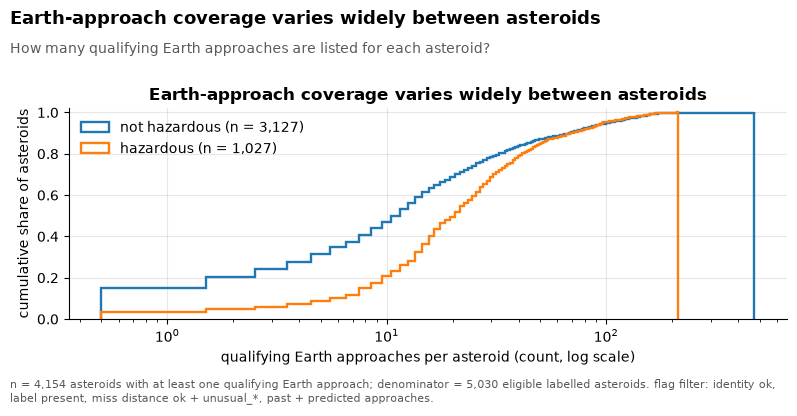

figures/m4_fig3_approach_coverage.png


In [12]:
# Cumulative distribution of listed Earth-approach counts per asteroid.
fig, ax = plt.subplots(figsize=(8, 4))
for hz, label in [(0, "not hazardous"), (1, "hazardous")]:
    vals = coverage.loc[(coverage.hazardous == hz) & (coverage.n_earth_approaches > 0), "n_earth_approaches"]
    ax.hist(vals, bins=np.arange(0.5, int(vals.max()) + 1.5, 1), histtype="step",
            lw=1.7, cumulative=True, density=True,
            label=f"{label} (n = {len(vals):,})")
ax.set_xscale("log")
ax.set(xlabel="qualifying Earth approaches per asteroid (count, log scale)",
       ylabel="cumulative share of asteroids", ylim=(0, 1.02))
ax.set_title("Earth-approach coverage varies widely between asteroids")
ax.legend()
path = finish(fig, "m4_fig3_approach_coverage",
              "Earth-approach coverage varies widely between asteroids",
              "How many qualifying Earth approaches are listed for each asteroid?",
              f"n = {int((coverage.n_earth_approaches > 0).sum()):,} asteroids with at least one qualifying Earth approach; denominator = {len(coverage):,} eligible labelled asteroids. {KEY_FILTER_TEXT}.")
plt.show()
print(path.relative_to(ROOT))


### 4.2 Key result with and without the coverage rule

The number of listed approaches varies substantially between asteroids. Approach rows must therefore not be treated as independent asteroid observations. The threshold is applied to the count of qualifying Earth approaches per asteroid; each asteroid still contributes one minimum distance to the median. The table below displays the result with no additional minimum and with the coverage rule.


In [13]:
def closest_by_coverage(df, min_approaches=1):
    selected = df.loc[df.n_earth_approaches >= min_approaches].copy()
    selected["closest_ld"] = selected.closest_km / LD_KM
    out = selected.groupby("hazardous")["closest_ld"].agg(n="size", median_LD="median").round(2)
    out.index = out.index.map({0: "not hazardous", 1: "hazardous"})
    return out

coverage_key_results = pd.concat(
    {"no minimum (>=1)": closest_by_coverage(coverage, 1),
     f"coverage rule (>= {MIN_EARTH_APPROACHES})": closest_by_coverage(coverage, MIN_EARTH_APPROACHES)},
    axis=1)
coverage_key_results


no minimum (>=1)           coverage rule (>= 3)          
                             n median_LD                    n median_LD
hazardous                                                              
not hazardous             3127     40.22                 2494     43.73
hazardous                 1027     13.07                  978     12.65

### 4.3 Sensitivity to the miss-distance flag filter

We compare the primary `KEY_FILTER` (valid plus `unusual_low`/`unusual_high` miss-distance values) with a stricter filter that retains only `miss_distance_km_flag = 'ok'`. Both filters keep the same identity, label, and timing rules. This isolates the effect of including unusual-but-retained measurements. We report `KEY_FILTER` as primary because M3 flags unusual values rather than declaring them invalid; excluding them could remove meaningful close approaches. Strict `ok` is a sensitivity check, not a replacement.


In [14]:
coverage_strict = query(con, COVERAGE_SQL, STRICT_OK_FILTER)
filter_comparison = pd.concat(
    {"KEY_FILTER (ok + unusual_*)": closest_by_coverage(coverage, 1),
     "strict ok only": closest_by_coverage(coverage_strict, 1)},
    axis=1)
filter_comparison


KEY_FILTER (ok + unusual_*)           strict ok only          
                                        n median_LD              n median_LD
hazardous                                                                   
not hazardous                        3127     40.22           3050     43.67
hazardous                            1027     13.07           1027     14.10

**Coverage and filter finding.** A minimum of three qualifying Earth approaches is used for coverage-qualified summaries (3,472/4,154 = 83.6% of asteroids with at least one qualifying approach in the supplied database); the unqualified result remains visible so the effect of this decision can be assessed. The primary reported estimate uses `KEY_FILTER` (identity resolved, label present, non-null miss distance, `ok` plus `unusual_*`, past and predicted); strict `ok` is reported as a sensitivity check. Neither policy removes the NASA listing-cut-off limitation described in §3.


## 5. Time  *(Rana Yalçın)*

Time is represented in UTC. We inspect the edges of the 1900–2200 analysis window, compare decade and annual coverage, and separate historical from predicted encounters using `timing_flag`.

All approach epochs are stored as Unix timestamps in milliseconds and are converted to timezone-aware UTC timestamps. UTC is appropriate because NASA's close-approach epochs are global event times, not local civil times; it avoids daylight-saving and timezone ambiguity across centuries. The same primary `KEY_FILTER` is used throughout unless stated otherwise.

The requested window is 1900–2200 inclusive. We inspect rather than silently clip its boundaries: one qualifying row falls on 1899-12-31, immediately outside the nominal window. The final decade bucket (2200–2209) can contain only the year 2200, so it is a one-year boundary slice, not a complete decade.


In [15]:
TIME_SQL = '''
SELECT p.asteroid_key, p.epoch_date_close_approach, p.timing_flag,
       p.miss_distance_km_flag, p.miss_distance_km
FROM approach_clean AS p
JOIN asteroid_clean AS c ON c.asteroid_key = p.asteroid_key
WHERE p.orbiting_body = 'Earth'
  AND c.identity_flag = 'ok'
  AND c.is_potentially_hazardous IS NOT NULL
  AND (c.is_potentially_hazardous_flag <> 'label_rule_mismatch' OR :exclude_label_mismatch = 0)
  AND p.miss_distance_km IS NOT NULL
  AND (p.miss_distance_km_flag = 'ok' OR :include_unusual = 1)
  AND (p.timing_flag = 'past' OR :include_predicted = 1)
'''
time = query(con, TIME_SQL, KEY_FILTER)
time["epoch_utc"] = pd.to_datetime(time.epoch_date_close_approach, unit="ms", utc=True)
time["year"] = time.epoch_utc.dt.year
time["decade"] = (time.year // 10) * 10
window = time.loc[time.year.between(1900, 2200)].copy()
outside_window = time.loc[~time.year.between(1900, 2200)].copy()
boundary_check = pd.DataFrame({
    "measure": ["all qualifying Earth approaches", "outside 1900–2200",
                "1899-12-31 row(s)", "year 1900", "year 2200"],
    "n_approaches": [len(time), len(outside_window), int((time.year == 1899).sum()),
                     int((time.year == 1900).sum()), int((time.year == 2200).sum())]
})
print("UTC range:", time.epoch_utc.min(), "to", time.epoch_utc.max())
boundary_check


UTC range: 1899-12-31 22:03:00+00:00 to 2200-12-31 15:37:00+00:00


,measure,n_approaches
0,all qualifying Earth approaches,106099
1,outside 1900–2200,1
2,1899-12-31 row(s),1
3,year 1900,360
4,year 2200,302


### 5.1 Decade and year scales; past versus predicted

We use two descriptive time scales. Decade totals reveal broad changes without over-interpreting individual years; annual totals expose variation hidden inside each decade. The number of years represented is included so the 2200 boundary bucket is explicitly marked as one year. The `timing_flag` is the relevant split: `past` records are historical close approaches and `predicted` records are future orbital predictions.


In [16]:
decade_counts = (window.groupby(["decade", "timing_flag"]).size()
                 .unstack(fill_value=0).reindex(columns=["past", "predicted"], fill_value=0))
# Make the period denominator explicit, including any empty decade buckets.
decade_counts = decade_counts.reindex(range(1900, 2201, 10), fill_value=0)
decade_counts["total"] = decade_counts[["past", "predicted"]].sum(axis=1)
decade_counts["years_in_window"] = [1 if d == 2200 else 10 for d in decade_counts.index]
years_with_approach = (window.groupby("decade")["year"].nunique()
                       .reindex(decade_counts.index, fill_value=0))
decade_counts["years_with_approach"] = years_with_approach.astype(int)
decade_counts["year_coverage_%"] = (
    100 * decade_counts.years_with_approach / decade_counts.years_in_window
).round(1)
decade_counts["approaches_per_year"] = (
    decade_counts.total / decade_counts.years_in_window
).round(1)
decade_counts

timing_flag,past,predicted,total,years_in_window,years_with_approach,year_coverage_%,approaches_per_year
decade,,,,,,,
1900,3397,0,3397,10,10,100.0,339.7
1910,3370,0,3370,10,10,100.0,337.0
1920,3319,0,3319,10,10,100.0,331.9
1930,3479,0,3479,10,10,100.0,347.9
1940,3522,0,3522,10,10,100.0,352.2
1950,3465,0,3465,10,10,100.0,346.5
1960,3581,0,3581,10,10,100.0,358.1
1970,3473,0,3473,10,10,100.0,347.3
1980,3525,0,3525,10,10,100.0,352.5


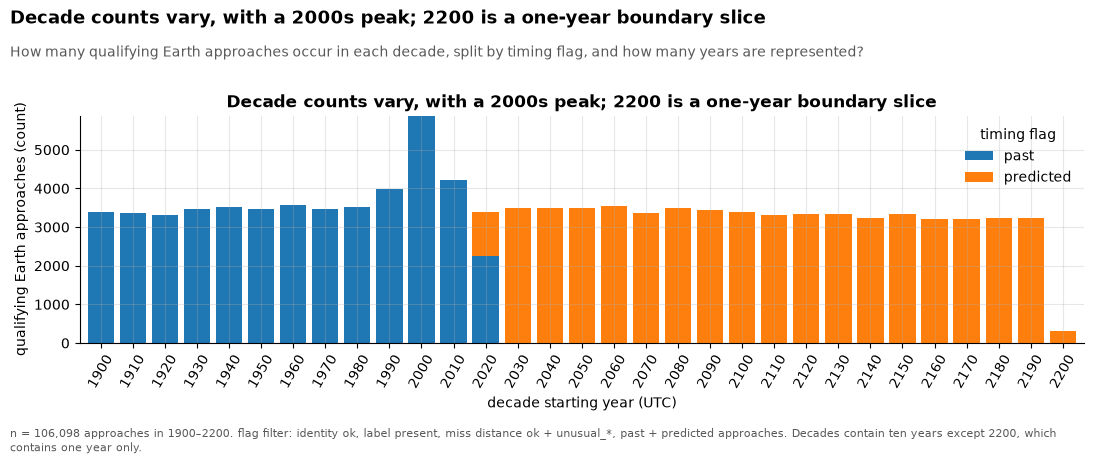

figures/m4_fig4_approaches_by_decade.png


In [17]:
fig, ax = plt.subplots(figsize=(11, 4.5))
decade_counts[["past", "predicted"]].plot(kind="bar", stacked=True, ax=ax, width=0.82)
ax.set(xlabel="decade starting year (UTC)", ylabel="qualifying Earth approaches (count)")
ax.set_title("Decade counts vary, with a 2000s peak; 2200 is a one-year boundary slice")
ax.tick_params(axis="x", rotation=60)
ax.set_ylim(bottom=0)
ax.legend(title="timing flag")
path = finish(fig, "m4_fig4_approaches_by_decade",
              "Decade counts vary, with a 2000s peak; 2200 is a one-year boundary slice",
              "How many qualifying Earth approaches occur in each decade, split by timing flag, and how many years are represented?",
              f"n = {len(window):,} approaches in 1900–2200. {KEY_FILTER_TEXT}. Decades contain ten years except 2200, which contains one year only.")
plt.show()
print(path.relative_to(ROOT))


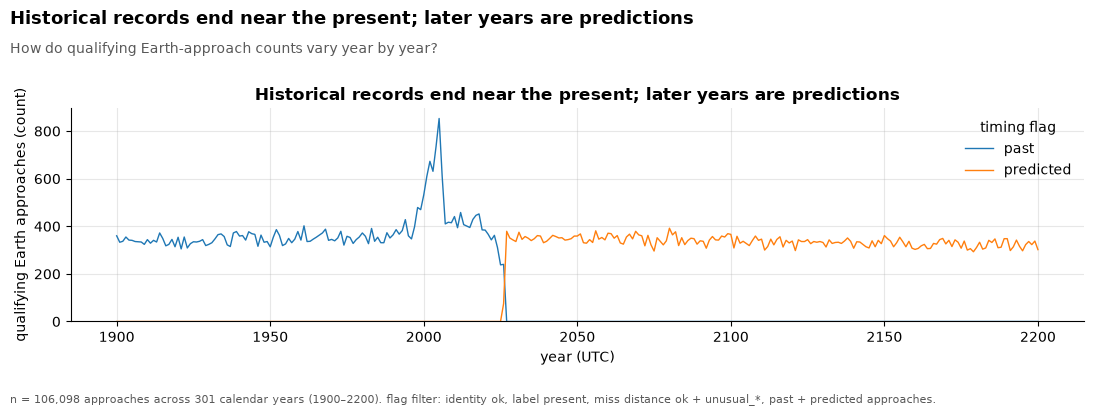

figures/m4_fig5_approaches_by_year.png


timing_flag,past,predicted,total
count,301.0,301.0,301.0
mean,157.6,194.8,352.5
std,192.4,167.0,58.2
min,0.0,0.0,238.0
25%,0.0,0.0,328.0
50%,0.0,312.0,342.0
75%,345.0,341.0,359.0
max,853.0,392.0,853.0


In [18]:
annual_counts = (window.groupby(["year", "timing_flag"]).size()
                 .unstack(fill_value=0).reindex(columns=["past", "predicted"], fill_value=0))
annual_counts["total"] = annual_counts.sum(axis=1)
annual_counts = annual_counts.reindex(range(1900, 2201), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(annual_counts.index, annual_counts["past"], lw=1.0, label="past")
ax.plot(annual_counts.index, annual_counts["predicted"], lw=1.0, label="predicted")
ax.set(xlabel="year (UTC)", ylabel="qualifying Earth approaches (count)")
ax.set_title("Historical records end near the present; later years are predictions")
ax.set_ylim(bottom=0)
ax.legend(title="timing flag")
path = finish(fig, "m4_fig5_approaches_by_year",
              "Historical records end near the present; later years are predictions",
              "How do qualifying Earth-approach counts vary year by year?",
              f"n = {len(window):,} approaches across {len(annual_counts):,} calendar years (1900–2200). {KEY_FILTER_TEXT}.")
plt.show()
print(path.relative_to(ROOT))
annual_counts.describe().round(1)


### 5.2 Calendar check and its replacement

A conventional calendar-season check (months, weekdays, leap years, or local seasons) is not a meaningful quality test for orbital mechanics. Close approaches are determined by orbital geometry and encounter timing, not by a human calendar; apparent monthly or weekday patterns would also be sensitive to the prediction horizon and feed listing rules. Instead, we check (1) UTC timestamp range and the 1900/2200 boundary counts, (2) decade and annual coverage, and (3) the `past`/`predicted` split. This tests temporal coverage and the historical-versus-forecast distinction without implying a calendar mechanism.

**Time finding.** The nominal window has one qualifying record just outside it on 1899-12-31. The 2200 bucket is necessarily incomplete because it contains only the single year 2200; decade totals are interpreted with this boundary caveat. The `timing_flag` split, rather than calendar season, distinguishes observed history from predicted future encounters. All timestamps and plotted year labels are UTC.


## 6. Relationships  *(Elif Şahin)*

**Which relationship, and why.** Section 4 showed that coverage is unequal: in this sample hazardous asteroids have a median of **21** listed Earth approaches
against **12** for the others, and an asteroid's closest approach is the minimum over those approaches. So before comparing the groups (section 7)
we ask what drives the *number* of approaches. The orbit is the obvious candidate: an asteroid on a small orbit comes round more often.
The relationship examined is **semi-major axis *a* (AU) versus the number of listed Earth approaches per asteroid**.
H, MOID and diameter are not used: they define the label.

**Data.** One row per asteroid from `sql/queries/asteroid_orbit_profile.sql` with the same `KEY_FILTER` as the key number. It needs an orbit row,
so it holds the key sample minus the asteroids without one. Orbit class (Apollo, Amor, Aten, Atira) is NASA's `orbit_class_type` from the M2
`orbits` table, because `orbit_clean` does not carry it; the query also recomputes it from *a* and *e* with NASA's class definitions
(perihelion *q* = *a*(1 − *e*), aphelion *Q* = *a*(1 + *e*)) as a check.

In [19]:
profile_sql = load_query("asteroid_orbit_profile")
prof = query(con, profile_sql, KEY_FILTER)
prof["closest_ld"] = prof["closest_km"] / LD_KM
missing = set(clean.asteroid_key) - set(prof.asteroid_key)
print(f"profile: n = {len(prof):,} asteroids ({(prof.hazardous == 1).sum():,} hazardous, {(prof.hazardous == 0).sum():,} not) | "
      f"{KEY_FILTER_TEXT}; orbit e, i, a present")
print(f"in the key sample but not here: {len(missing)} asteroids (no orbit row in orbit_clean)")
print(f"orbit class: NASA orbit_class_type vs class recomputed with a and e: {(prof.orbit_class != prof.derived_class).sum()} mismatches")
pd.crosstab(prof.orbit_class, prof.hazardous.map(names).rename("label"), margins=True, margins_name="total")

profile: n = 4,124 asteroids (1,021 hazardous, 3,103 not) | flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches; orbit e, i, a present
in the key sample but not here: 30 asteroids (no orbit row in orbit_clean)
orbit class: NASA orbit_class_type vs class recomputed with a and e: 0 mismatches


label,hazardous,not hazardous,total
orbit_class,,,
AMO,58,1282,1340
APO,855,1541,2396
ATE,106,276,382
IEO,2,4,6
total,1021,3103,4124


In [20]:
# Every pair looked at before choosing one (counted in section 7). Spearman = Pearson on ranks (no scipy needed).
def spearman(x, y):
    return x.rank().corr(y.rank())

prof["perihelion"] = prof["perihelion_au"]
features = {"eccentricity": "e", "inclination": "i (deg)", "semi_major_axis": "a (AU)", "perihelion": "q (AU)",
            "mean_velocity_km_s": "mean Earth-approach velocity (km/s)"}
targets = {"n_earth_approaches": "listed Earth approaches", "closest_ld": "closest Earth approach (LD)"}
scan = pd.DataFrame([{"feature": fl, "versus": tl, "Pearson": prof[f].corr(prof[t]), "Spearman": spearman(prof[f], prof[t])}
                     for t, tl in targets.items() for f, fl in features.items()]).round(3)
print(f"pairs scanned: {len(scan)} | n = {len(prof):,} asteroids | {KEY_FILTER_TEXT}")
scan.sort_values("Spearman", key=abs, ascending=False)

pairs scanned: 10 | n = 4,124 asteroids | flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches


,feature,versus,Pearson,Spearman
2,a (AU),listed Earth approaches,-0.494,-0.578
8,q (AU),closest Earth approach (LD),0.399,0.445
3,q (AU),listed Earth approaches,-0.337,-0.379
6,i (deg),closest Earth approach (LD),0.287,0.373
0,e,listed Earth approaches,-0.286,-0.285
7,a (AU),closest Earth approach (LD),0.271,0.279
4,mean Earth-approach velocity (km/s),listed Earth approaches,0.033,0.135
9,mean Earth-approach velocity (km/s),closest Earth approach (LD),-0.090,-0.087
1,i (deg),listed Earth approaches,-0.015,0.033
5,e,closest Earth approach (LD),-0.004,-0.002


**Why *a* versus approach count.** The scan (ten pairs, all shown) has two strong orbit–approach links: *a* with the number of listed approaches
(Spearman ≈ −0.58) and perihelion *q* with the closest approach (≈ +0.45). The second is close to the label's own geometry — a small perihelion
near 1 AU is how an orbit gets a small MOID — so it would partly restate the definition. The first is about **coverage**, which section 4
showed is unequal between the groups, so it is the one that matters for reading the key comparison. Velocity is a property of the approaches
themselves, not of the orbit, and is left for M7.

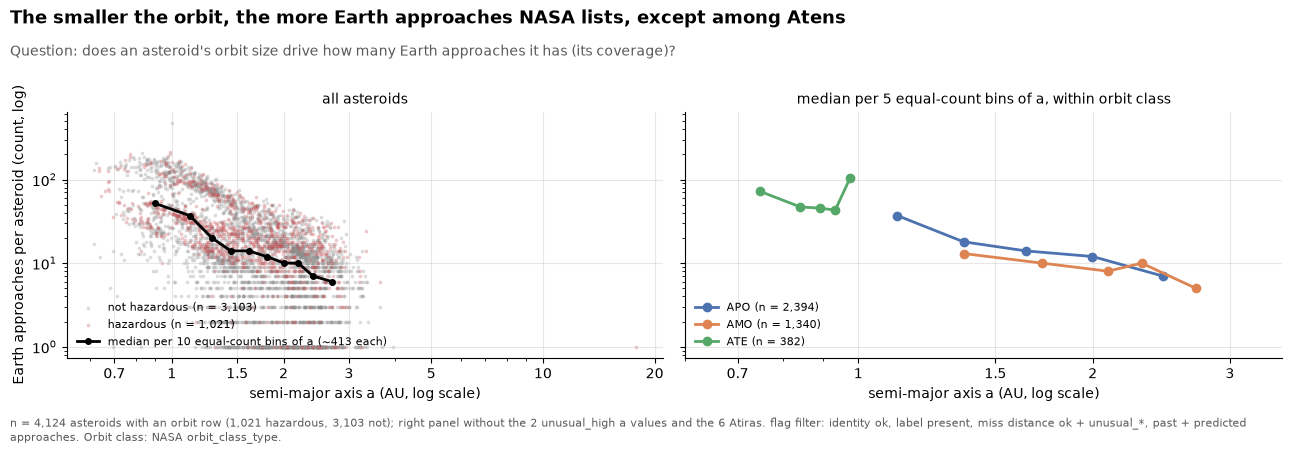

figures/m4_fig6_axis_vs_approaches.png


In [21]:
trimmed = prof[prof.semi_major_axis_flag == "ok"]      # drops the M3 unusual_high values of a (robust z > 3.5)
prof["a_bin"] = pd.qcut(prof.semi_major_axis, N_A_BINS)
binned = prof.groupby("a_bin", observed=True).agg(a_median=("semi_major_axis", "median"),
                                                  n_median=("n_earth_approaches", "median"), n=("asteroid_key", "size"))
class_colors = {"APO": "#4C72B0", "AMO": "#DD8452", "ATE": "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
ax = axes[0]
for hz in (0, 1):
    s = prof[prof.hazardous == hz]
    ax.scatter(s.semi_major_axis, s.n_earth_approaches, s=7, alpha=0.3, lw=0, color=colors[hz], label=f"{names[hz]} (n = {len(s):,})")
ax.plot(binned.a_median, binned.n_median, color="black", lw=2, marker="o", ms=4,
        label=f"median per {N_A_BINS} equal-count bins of a (~{binned.n.iloc[0]} each)")
ax.set(xscale="log", yscale="log", xlabel="semi-major axis a (AU, log scale)",
       ylabel="Earth approaches per asteroid (count, log)")
ax.set_title("all asteroids", fontsize=10, fontweight="normal")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
for cls, col in class_colors.items():
    g = trimmed[trimmed.orbit_class == cls].copy()
    g["bin"] = pd.qcut(g.semi_major_axis, 5)
    b = g.groupby("bin", observed=True).agg(a=("semi_major_axis", "median"), m=("n_earth_approaches", "median"))
    ax.plot(b.a, b.m, marker="o", lw=2, color=col, label=f"{cls} (n = {len(g):,})")
ax.set(xscale="log", xlabel="semi-major axis a (AU, log scale)")
for ax in axes:
    ax.set_xticks([0.7, 1, 1.5, 2, 3, 5, 10, 20])
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set_xlim(0.6, 3.5)
ax.set_title("median per 5 equal-count bins of a, within orbit class", fontsize=10, fontweight="normal")
ax.legend(loc="lower left", fontsize=8)
path = finish(fig, "m4_fig6_axis_vs_approaches",
              "The smaller the orbit, the more Earth approaches NASA lists, except among Atens",
              "Question: does an asteroid's orbit size drive how many Earth approaches it has (its coverage)?",
              f"n = {len(prof):,} asteroids with an orbit row ({(prof.hazardous == 1).sum():,} hazardous, {(prof.hazardous == 0).sum():,} not); "
              f"right panel without the {len(prof) - len(trimmed)} unusual_high a values and the {(trimmed.orbit_class == 'IEO').sum()} Atiras. "
              f"{KEY_FILTER_TEXT}. Orbit class: NASA orbit_class_type.")
plt.show()
print(path.relative_to(ROOT))

In [22]:
def corr_row(label, d):
    return {"subset": label, "n": len(d),
            "Pearson": d.semi_major_axis.corr(d.n_earth_approaches),
            "Spearman": spearman(d.semi_major_axis, d.n_earth_approaches)}

extremes = prof.loc[prof.semi_major_axis_flag != "ok", ["asteroid_key", "semi_major_axis", "orbit_class", "hazardous", "n_earth_approaches"]]
print("extreme points removed (semi_major_axis_flag = unusual_high):")
print(extremes.to_string(index=False))
rows = [corr_row("all asteroids", prof), corr_row("without the unusual_high a values", trimmed)]
for cls, g in trimmed.groupby("orbit_class"):
    if len(g) >= MIN_CLASS_N:
        rows.append(corr_row(f"within {cls}", g))
    else:
        print(f"{cls}: n = {len(g)} < MIN_CLASS_N = {MIN_CLASS_N}, no correlation reported")
for (cls, hz), g in trimmed.groupby(["orbit_class", "hazardous"]):
    if len(g) >= MIN_CLASS_N:
        rows.append(corr_row(f"within {cls}, {names[hz]}", g))
print(f"a vs listed Earth approaches | {KEY_FILTER_TEXT}")
pd.DataFrame(rows).round(3)

extreme points removed (semi_major_axis_flag = unusual_high):
 asteroid_key  semi_major_axis orbit_class  hazardous  n_earth_approaches
         3177        17.814613         APO          1                   1
         3496         3.633027         APO          1                   6
IEO: n = 6 < MIN_CLASS_N = 10, no correlation reported
a vs listed Earth approaches | flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches


,subset,n,Pearson,Spearman
0,all asteroids,4124,-0.494,-0.578
1,without the unusual_high a values,4122,-0.534,-0.577
2,within AMO,1340,-0.445,-0.358
3,within APO,2394,-0.459,-0.500
4,within ATE,382,-0.012,0.012
5,"within AMO, not hazardous",1282,-0.438,-0.347
6,"within AMO, hazardous",58,-0.565,-0.589
7,"within APO, not hazardous",1541,-0.450,-0.497
8,"within APO, hazardous",853,-0.496,-0.568
9,"within ATE, not hazardous",276,-0.008,0.020


**Relationship finding.** Asteroids on smaller orbits have more listed Earth approaches: the binned medians fall from about **52** approaches
for the smallest tenth of orbits (*a* < 1 AU) to about **6** for the largest tenth (*a* > 2.5 AU), and the rank correlation is **−0.58**.
The relationship is **monotone but not linear** (it bends on log scales), which is why Pearson (−0.49) is weaker than Spearman.
**Removing the extreme points** — the two values of *a* that M3 flagged `unusual_high`, among them a hazardous asteroid at *a* = 17.8 AU with a
single approach — moves Pearson from −0.49 to −0.53 and leaves Spearman unchanged (−0.58): one far point was pulling the linear fit, the ranks do
not care. **Within orbit class** the link holds for Apollos (−0.50) and Amors (−0.36) and holds in both label groups, but **disappears for Atens**
(≈ 0.0): Atens all have *a* < 1 AU and cross Earth's orbit from inside, so they come round often whatever their exact *a*.
The six Atiras are too few for a correlation.

*So what for the question:* the number of approaches an asteroid gets — and with it the chance that its listed minimum is small — depends on the
orbit class and the orbit size, and the two label groups have different orbit mixes (section 7). Coverage and orbit class have to be held
fixed before the closest-approach gap is read as a property of the label.

## 7. One comparison, with an interval  *(Elif Şahin)*

**Comparison:** hazardous minus non-hazardous **median closest Earth approach** (LD), the key number of section 1. The unit is the **asteroid**
(one closest value each), so the bootstrap resamples asteroids, not approaches: `bootstrap_ci(a, b, n_boot=N_BOOT, seed=SEED)`, percentile 95% interval.

**Composition check first.** If the two groups have a different mix of orbit classes or of coverage, the overall gap can come from the mix
rather than from the label (Simpson's paradox). So we look at the mix, then repeat the comparison within each orbit class.

In [23]:
label = prof.hazardous.map(names).rename("label")
mix = pd.crosstab(prof.orbit_class, label, normalize="columns") * 100
mix_n = pd.crosstab(prof.orbit_class, label)
cov = prof.pivot_table(index="orbit_class", columns=label, values="n_earth_approaches", aggfunc="median")
composition = pd.concat({"share of group (%)": mix.round(1), "asteroids": mix_n, "median listed Earth approaches": cov}, axis=1)
print(f"n = {len(prof):,} asteroids | {KEY_FILTER_TEXT}")
composition

n = 4,124 asteroids | flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches


share of group (%)               asteroids                \
label                hazardous not hazardous hazardous not hazardous   
orbit_class                                                            
AMO                        5.7          41.3        58          1282   
APO                       83.7          49.7       855          1541   
ATE                       10.4           8.9       106           276   
IEO                        0.2           0.1         2             4   

            median listed Earth approaches                
label                            hazardous not hazardous  
orbit_class                                               
AMO                                   11.5           9.0  
APO                                   19.0          12.0  
ATE                                   49.5          53.5  
IEO                                   80.5          11.0

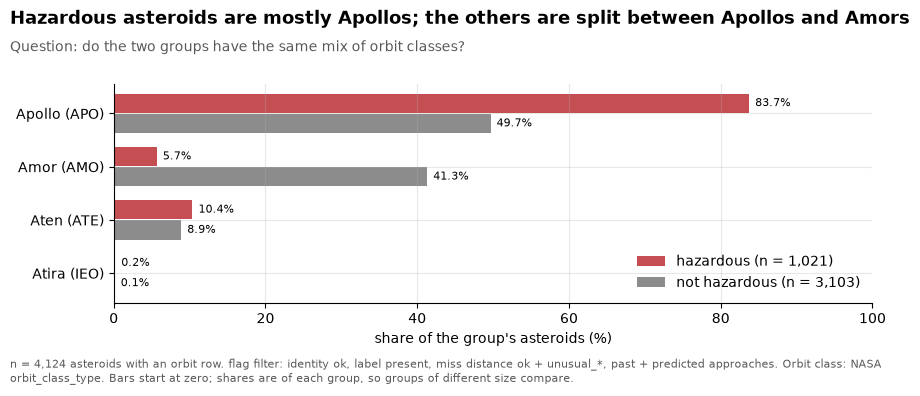

figures/m4_fig7_orbit_class_mix.png


In [24]:
order = ["APO", "AMO", "ATE", "IEO"]
labels = {"APO": "Apollo (APO)", "AMO": "Amor (AMO)", "ATE": "Aten (ATE)", "IEO": "Atira (IEO)"}
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(order))
for k, hz in enumerate((1, 0)):
    vals = mix.reindex(order)[names[hz]].fillna(0).values
    n_g = (prof.hazardous == hz).sum()
    ax.barh(y + (k - 0.5) * 0.38, vals, height=0.36, color=colors[hz], label=f"{names[hz]} (n = {n_g:,})")
    for yy, v in zip(y + (k - 0.5) * 0.38, vals):
        ax.text(v + 0.8, yy, f"{v:.1f}%", va="center", fontsize=8)
ax.set_yticks(y, [labels[c] for c in order])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of the group's asteroids (%)")
ax.legend(loc="lower right")
path = finish(fig, "m4_fig7_orbit_class_mix",
              "Hazardous asteroids are mostly Apollos; the others are split between Apollos and Amors",
              "Question: do the two groups have the same mix of orbit classes?",
              f"n = {len(prof):,} asteroids with an orbit row. {KEY_FILTER_TEXT}. Orbit class: NASA orbit_class_type. "
              "Bars start at zero; shares are of each group, so groups of different size compare.")
plt.show()
print(path.relative_to(ROOT))

In [25]:
def gap(d, subset, coverage):
    a = d.loc[d.hazardous == 1, "closest_ld"]
    b = d.loc[d.hazardous == 0, "closest_ld"]
    if min(len(a), len(b)) < MIN_CLASS_N:
        return None
    diff, lo, hi = bootstrap_ci(a, b, n_boot=N_BOOT, seed=SEED)
    return {"subset": subset, "coverage": coverage, "n hazardous": len(a), "n not": len(b),
            "median hazardous (LD)": a.median(), "median not (LD)": b.median(),
            "difference (LD)": diff, "95% CI low": lo, "95% CI high": hi}

rows, skipped = [], []
for coverage, keep in [("all", 1), (f">= {MIN_EARTH_APPROACHES} approaches", MIN_EARTH_APPROACHES)]:
    tests = [("key sample (section 1)", clean[clean.n_earth_approaches >= keep]),
             ("with orbit row", prof[prof.n_earth_approaches >= keep])]
    tests += [(f"within {c}", g) for c, g in prof[prof.n_earth_approaches >= keep].groupby("orbit_class")]
    for subset, d in tests:
        r = gap(d, subset, coverage)
        (rows.append(r) if r else skipped.append(f"{subset} ({coverage})"))
gaps = pd.DataFrame(rows)
print(f"intervals computed: {len(gaps)} | skipped (a group below MIN_CLASS_N = {MIN_CLASS_N}): {skipped}")
print(f"bootstrap: {N_BOOT} resamples of asteroids, seed {SEED}, percentile 95% interval | {KEY_FILTER_TEXT}")

# Class-mix-adjusted gap: within-class differences weighted by the classes' share of all asteroids (direct standardisation)
for coverage, g in gaps[gaps.subset.str.startswith("within")].groupby("coverage", sort=False):
    w = g["n hazardous"] + g["n not"]
    print(f"class-mix-adjusted difference ({coverage}): {np.average(g['difference (LD)'], weights=w):.1f} LD "
          f"(weights = asteroids per class, n = {w.sum():,})")
gaps.round(2)

intervals computed: 10 | skipped (a group below MIN_CLASS_N = 10): ['within IEO (all)', 'within IEO (>= 3 approaches)']
bootstrap: 2000 resamples of asteroids, seed 42, percentile 95% interval | flag filter: identity ok, label present, miss distance ok + unusual_*, past + predicted approaches
class-mix-adjusted difference (all): -23.4 LD (weights = asteroids per class, n = 4,118)
class-mix-adjusted difference (>= 3 approaches): -26.8 LD (weights = asteroids per class, n = 3,467)


,subset,coverage,n hazardous,n not,median hazardous (LD),median not (LD),difference (LD),95% CI low,95% CI high
0,key sample (section 1),all,1027,3127,13.07,40.22,-27.15,-29.05,-25.67
1,with orbit row,all,1021,3103,13.05,39.93,-26.88,-28.76,-25.38
2,within AMO,all,58,1282,19.19,61.57,-42.37,-45.51,-38.57
3,within APO,all,855,1541,12.99,27.61,-14.62,-16.84,-12.62
4,within ATE,all,106,276,9.79,22.10,-12.31,-18.08,-9.29
5,key sample (section 1),>= 3 approaches,978,2494,12.65,43.73,-31.08,-33.26,-29.07
6,with orbit row,>= 3 approaches,978,2494,12.65,43.73,-31.08,-33.26,-29.07
7,within AMO,>= 3 approaches,56,1035,18.96,62.51,-43.55,-47.29,-40.58
8,within APO,>= 3 approaches,814,1181,12.57,32.91,-20.34,-22.08,-18.57
9,within ATE,>= 3 approaches,106,275,9.79,22.10,-12.32,-18.36,-9.45


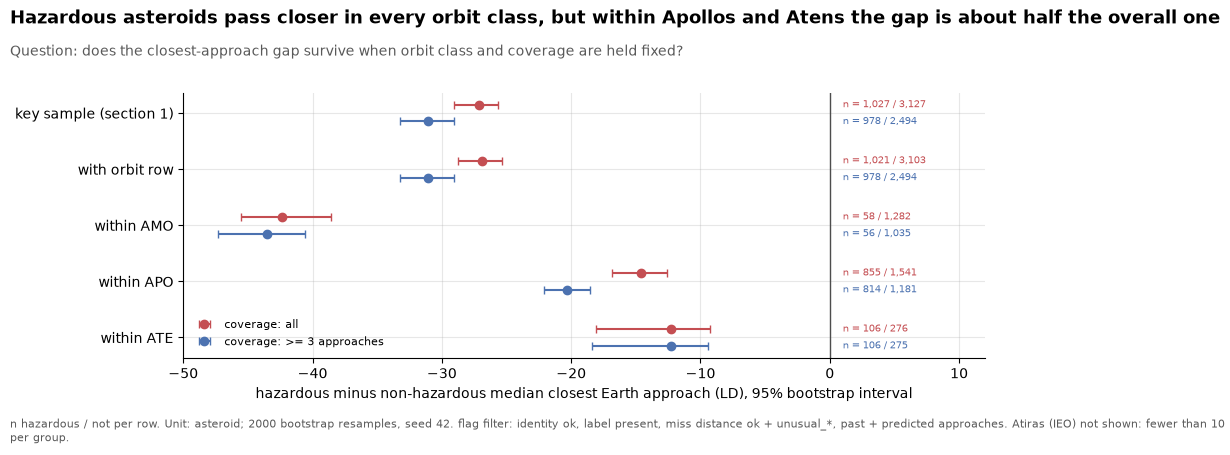

figures/m4_fig8_gap_within_class.png


In [26]:
fig, ax = plt.subplots(figsize=(10, 4.4))
subsets = list(dict.fromkeys(gaps.subset))
y = np.arange(len(subsets))
for k, (coverage, col) in enumerate(zip(gaps.coverage.unique(), ("#C44E52", "#4C72B0"))):
    g = gaps[gaps.coverage == coverage].set_index("subset").reindex(subsets)
    yy = y + (k - 0.5) * 0.3
    ax.errorbar(g["difference (LD)"], yy, xerr=[g["difference (LD)"] - g["95% CI low"], g["95% CI high"] - g["difference (LD)"]],
                fmt="o", color=col, capsize=3, label=f"coverage: {coverage}")
    for v, n1, n0, yv in zip(g["difference (LD)"], g["n hazardous"], g["n not"], yy):
        if pd.notna(v):
            ax.text(1.0, yv, f"n = {int(n1):,} / {int(n0):,}", va="center", fontsize=7, color=col)
ax.axvline(0, color="0.3", lw=1)
ax.set_yticks(y, subsets)
ax.invert_yaxis()
ax.set_xlim(-50, 12)
ax.set_xlabel("hazardous minus non-hazardous median closest Earth approach (LD), 95% bootstrap interval")
ax.legend(loc="lower left", fontsize=8)
path = finish(fig, "m4_fig8_gap_within_class",
              "Hazardous asteroids pass closer in every orbit class, but within Apollos and Atens the gap is about half the overall one",
              "Question: does the closest-approach gap survive when orbit class and coverage are held fixed?",
              f"n hazardous / not per row. Unit: asteroid; {N_BOOT} bootstrap resamples, seed {SEED}. {KEY_FILTER_TEXT}. "
              f"Atiras (IEO) not shown: fewer than {MIN_CLASS_N} per group.")
plt.show()
print(path.relative_to(ROOT))

**Comparison finding.** Overall, hazardous asteroids' median closest approach is **27.1 LD closer** (13.1 vs 40.2 LD; 95% CI −29.1 to −25.7 LD;
n = 1,027 vs 3,127 asteroids). **The groups are not comparable as a whole:** 84% of hazardous asteroids are Apollos against 50% of the others,
and 41% of the others are Amors
(Amors never cross Earth's orbit, so their closest passes are far). **Within orbit class** the gap keeps its sign everywhere — so there is
**no Simpson reversal** — but it shrinks to about **−15 LD among Apollos** and **−12 LD among Atens**, and grows to about **−42 LD among Amors**,
where the 58 hazardous Amors are the few whose perihelion reaches close to Earth's orbit. Weighting the within-class gaps by class size gives
**−23.4 LD** against −26.9 LD for the same asteroids unweighted, so about **3.5 LD (an eighth) of the overall gap is orbit-class mix**.
Requiring at least three listed approaches (section 4) widens the overall gap (−27.1 → −31.1 LD) and the Apollo gap (−14.6 → −20.3 LD),
leaves Atens unchanged and changes no sign. **Part of the gap is by construction**: the label requires MOID ≤ 0.05 AU (19.5 LD), and a pass
cannot be closer than the MOID; this comparison describes the size of the gap, it does not show that closeness *causes* the label.

**How many comparisons were looked at.** Section 6 scanned **10** feature pairs and reported **one** relationship (with 10 recomputations:
without extremes, within 3 classes, within 6 class × label groups). Section 7 computed **10** intervals (5 subsets × 2 coverage rules) and
2 class-mix-adjusted gaps, and skipped the Atiras under both coverage rules (6 asteroids, too few). Nothing else was tried. With this many looks, a single interval that just excludes zero would be weak evidence; here
every interval is far from zero, but the within-class sizes are the numbers to quote, not the overall one.

## 8. Findings

| ID | Finding (one sentence) | Evidence | Label | What would change it | Explored by |
|---|---|---|---|---|---|
| F-01 | Hazardous asteroids' median closest Earth approach is about three times closer than non-hazardous ones' (13.1 vs 40.2 LD; n = 1,027 vs 3,127). | §2 table; `figures/m4_fig2_closest_by_group.png` | Exploratory — and partly **by construction** (the label requires MOID ≤ 0.05 AU) | Comparing at equal coverage (number of listed approaches), or within orbit class | Burak Avşar |
| F-02 | The share of asteroids that ever pass closer than the Moon is the same in both groups (~1.2–1.3%); those close passers without the label are small (H > 22). | §2 tables; ECDF in fig 2 | Exploratory | A size-matched comparison (same H range); more close passes (only 52 asteroids: 40 + 12) | Burak Avşar |
| F-03 | Cleaning barely changes the key number: only the 3 duplicate NASA ids drop out (hazardous median 13.08 → 13.07 LD) and no closest distance changes. | §1 queries and table | Confirmed (arithmetic: 0 invalid miss distances, 3 identity duplicates) | A new retrieval with invalid miss distances or more duplicate ids | Burak Avşar |
| F-04 | Closest approach is right-skewed in both groups; three quarters of hazardous asteroids pass within 0.05 AU and their histogram drops right after it. | `figures/m4_fig1_hist_bin_widths.png`, fig 2, §3 skew numbers | Exploratory (drop at 0.05 AU partly by construction) | Using MOID-free features only; a different time window | Burak Avşar |
| F-05 | NASA lists Earth approaches to two cut-offs (farthest passes pile up below 0.2 AU for 1,594 asteroids and below 0.5 AU for 1,838), which creates a step at ~78 LD; the hazardous / non-hazardous gap holds within each. | §3 farthest-approach table | Exploratory; cause unknown | NASA documentation of the listing rule; a retrieval where the cut-off is requested explicitly | Burak Avşar |
| F-06 | Earth-approach coverage is unequal; requiring at least three qualifying approaches reduces the influence of one- and two-record minima while retaining most eligible asteroids. | §4 coverage table and `figures/m4_fig3_approach_coverage.png`; key-number table with and without rule | Exploratory; threshold is a sensitivity rule, not proof of complete coverage | A documented NASA completeness denominator or a different minimum-approach threshold | Rana Yalçın |
| F-07 | The key median comparison is tested under two miss-distance flag policies; `KEY_FILTER` is primary and strict `ok` is a sensitivity check. | §4 flag-filter comparison | Exploratory | Independent validation of unusual values or a revised M3 flag policy | Rana Yalçın |
| F-08 | The 1900–2200 window has one qualifying approach just outside its start boundary and an incomplete 2200 decade; past/predicted timing is more meaningful than a calendar-season check. | §5 boundary table; `figures/m4_fig4_approaches_by_decade.png`; `figures/m4_fig5_approaches_by_year.png` | Descriptive coverage finding | A revised extraction window or documented NASA epoch/listing policy | Rana Yalçın |
| F-09 | Asteroids on smaller orbits have more listed Earth approaches (Spearman −0.58, n = 4,124; binned median ~52 approaches for *a* < 1 AU, ~6 for *a* > 2.5 AU); the link holds within Apollos (−0.50) and Amors (−0.36) but is absent within Atens (≈ 0). | §6 scan and correlation tables; `figures/m4_fig6_axis_vs_approaches.png` | Exploratory; robust to removing the 2 `unusual_high` values of *a* (Pearson −0.49 → −0.53, Spearman unchanged) | NASA documentation of how many approaches are listed per asteroid (the count may follow the listing rule as much as the orbit); a different time window | Elif Şahin |
| F-10 | The two groups have different orbit-class mixes: 84% of hazardous asteroids are Apollos against 50% of the others, and 41% of the others are Amors against 6%. | §7 composition table; `figures/m4_fig7_orbit_class_mix.png` | Descriptive; orbit class is NASA's `orbit_class_type` (0 mismatches with the class recomputed from *a* and *e*) | A sample not drawn in NASA's browse order (the mix is a property of this sample, not of all near-Earth asteroids) | Elif Şahin |
| F-11 | Hazardous asteroids pass closer in every orbit class (no Simpson reversal), but the gap is about half as large within Apollos (−14.6 LD, 95% CI −16.8 to −12.6) and Atens (−12.3 LD, −18.1 to −9.3) as overall (−27.1 LD, −29.1 to −25.7); weighting by class gives −23.4 LD. | §7 interval table; `figures/m4_fig8_gap_within_class.png` | Exploratory, partly by construction (MOID ≤ 0.05 AU); one of 10 intervals looked at, unit = asteroid, 2,000 resamples | Holding coverage and orbit class fixed together (finer strata); a sample with more Amors and Atiras | Elif Şahin |

### Back to cleaning
* **Missed by the cleaned layer:** the listing cut-off of each asteroid's Earth approaches (0.2 or 0.5 AU, F-05). It is coverage information an analysis
  needs; added to the M3 issues register (I-13, inferred) and, if the team agrees, as a column in `asteroid_clean`. Nothing the layer got *wrong*:
  the key number is unchanged by cleaning (F-03).
* **Orbit class not carried into the cleaned layer** (F-10): `orbits.orbit_class_type` exists in M2, but `orbit_clean` drops it, so §6–7 join back
  to `orbits`. It is the strongest confounder found in M4, so it belongs in `orbit_clean` (M3 issues register I-14).
* **Asteroids without an orbit row:** 30 asteroids in the key sample have Earth approaches but no `orbit_clean` row, so every orbit-based result
  (§6–7) is on 4,124 asteroids, not 4,154 (they are among the 33 feed-only asteroids already flagged `unchecked_no_orbit`, I-02; register I-15).

### Forward to modelling
* **Leakage:** H, MOID and diameter define the label; the closest Earth approach is bounded below by MOID, so it partly leaks the label too (F-01, F-04).
  M7 should treat it with care, or use it only as a check, not as a feature.
* **Size matters for the label but not for closeness:** the closest passes include many small, non-hazardous asteroids (F-02); a model must not learn
  "close pass ⇒ hazardous".
* **Unequal coverage:** an asteroid's closest approach depends on how many approaches NASA lists for it (1 to 473); M7 should retain a per-asteroid approach-count feature and test the minimum-coverage rule from §4. This is observed coverage, not complete physical coverage, because §3 suggests two farthest-approach cut-offs (0.2 and 0.5 AU).
* **Temporal coverage:** do not interpret the 2200 decade as a full decade; preserve `timing_flag` so historical observations and predicted encounters are not mixed without an explicit modelling decision (§5).
* **Orbit class is a confounder** (F-10, F-11): the label groups have different orbit mixes, and the closest-approach gap halves within Apollos and
  Atens. M7 should stratify by orbit class (or include it) and report within-class effects, not only pooled ones; Atiras (6 asteroids) are too few to model.
* **Orbit size drives coverage** (F-09): *a* and the number of listed approaches are strongly linked (Spearman −0.58), so a model given both sees
  the same signal twice; approach-based features should be read together with the approach count.
* **Unit of resampling:** any interval or cross-validation split must be by asteroid, not by approach (one asteroid has up to 473 approaches).

## 9. Decisions and database check

In [27]:
if "con" in globals() and con is not None:
    con.close()
    con = None
else:
    print("connection was not open; database fingerprint check will still run")
print("parameters used:")
for k in ["LD_KM", "AU_KM", "PHA_MOID_LD", "KEY_FILTER", "BIN_WIDTHS_LD", "CHOSEN_BIN_LD", "CLOSE_PASS_LD",
          "MIN_EARTH_APPROACHES", "SEED", "N_BOOT",
          "MIN_CLASS_N", "N_A_BINS"]:
    print(f"  {k} = {globals()[k]!r}")
print("figures written:", sorted(p.name for p in (ROOT / "figures").glob("m4_*.png")))
after = db_fingerprint()
print("database unchanged:", after == DB_FINGERPRINT_BEFORE)
assert after == DB_FINGERPRINT_BEFORE, "the notebook changed the database"

parameters used:
  LD_KM = 384400
  AU_KM = 149597870.7
  PHA_MOID_LD = 19.458620018210198
  KEY_FILTER = {'include_unusual': 1, 'include_predicted': 1, 'exclude_label_mismatch': 0}
  BIN_WIDTHS_LD = (1, 5, 10)
  CHOSEN_BIN_LD = 5
  CLOSE_PASS_LD = 1
  MIN_EARTH_APPROACHES = 3
  SEED = 42
  N_BOOT = 2000
  MIN_CLASS_N = 10
  N_A_BINS = 10
figures written: ['m4_fig1_hist_bin_widths.png', 'm4_fig2_closest_by_group.png', 'm4_fig3_approach_coverage.png', 'm4_fig4_approaches_by_decade.png', 'm4_fig5_approaches_by_year.png', 'm4_fig6_axis_vs_approaches.png', 'm4_fig7_orbit_class_mix.png', 'm4_fig8_gap_within_class.png']
database unchanged: True
